In [ ]:
# pip install pyfixest[jax]

In [ ]:
# !pip install linearmodels

In [ ]:
import pandas as pd
import statsmodels.formula.api as smf
import seaborn as sns
import matplotlib.pyplot as plt
from pyfixest.estimation import feols
import scipy.stats
import numpy as np
from matplotlib.lines import Line2D
import linearmodels as lm



from google.colab import drive
drive.mount('/content/gdrive')

attendance_df = pd.read_csv(r'/content/gdrive/My Drive/ECON 692/WNBA All Game Attendance - All Game Attendance.csv')

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


In [ ]:
attendance_df.head()

,Unnamed: 0,Year,Day of Week,Month,Day,Time (ET),Game Type,Home Team,Away Team,Arena,City,State,Attendance
0,1,1997,Saturday,June,21,4:00 PM,Regular season,Los Angeles Sparks,New York Liberty,Great Western Forum,Los Angeles,CA,14284
1,2,1997,Saturday,June,21,7:00 PM,Regular season,Cleveland Rockers,Houston Comets,Quicken Loans Arena,Cleveland,OH,11455
2,3,1997,Saturday,June,21,5:00 AM,Regular season,Utah Starzz,Sacramento Monarchs,EnergySolutions Arena,Salt Lake City,UT,8915
3,4,1997,Sunday,June,22,4:00 PM,Regular season,Phoenix Mercury,Charlotte Sting,US Airways Center,Phoenix,AZ,16102
4,5,1997,Monday,June,23,3:00 AM,Regular season,Utah Starzz,Los Angeles Sparks,EnergySolutions Arena,Salt Lake City,UT,8036


                          PanelOLS Estimation Summary                           
Dep. Variable:             Attendance   R-squared:                        0.0238
Estimator:                   PanelOLS   R-squared (Between):             -0.0034
No. Observations:                6214   R-squared (Within):               0.0416
Date:                Mon, Apr 07 2025   R-squared (Overall):             -0.0038
Time:                        06:24:27   Log-likelihood                -5.782e+04
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      29.973
Entities:                          29   P-value                           0.0000
Avg Obs:                       214.28   Distribution:                  F(5,6154)
Min Obs:                       1.0000                                           
Max Obs:                       503.00   F-statistic (robust):             33.681
                            

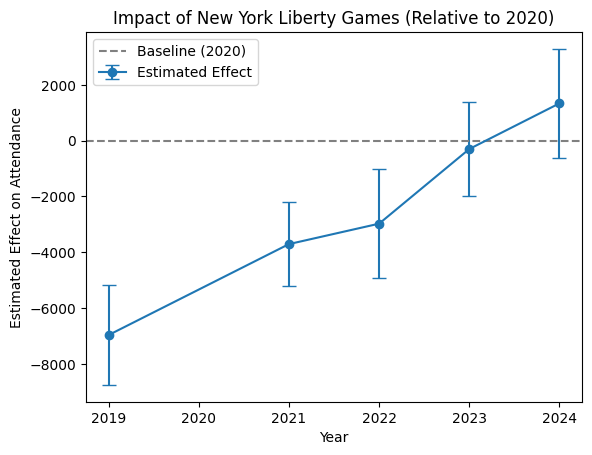

In [ ]:
# New York Liberty (Sabrina Ionescu)
ny_attendance_df = attendance_df.copy()

# 🚀 2. Create Treatment Variable for New York Liberty Games (2020-2024)
ny_attendance_df['NY_Liberty_Game'] = (ny_attendance_df['Home Team'] == 'New York Liberty') & (ny_attendance_df['Year'].between(2019, 2024))

# 🚀 3. Create Interaction Terms for Each Year (Skip 2020 as the Reference)
for year in [2019, 2021, 2022, 2023, 2024]:
    col_name = f'INX{year}'
    ny_attendance_df[col_name] = ny_attendance_df['NY_Liberty_Game'].astype(int)
    ny_attendance_df.loc[ny_attendance_df['Year'] != year, col_name] = 0

# 🚀 4. Set Index for Panel Data (Team and Year)
ny_attendance_df = ny_attendance_df.set_index(['Home Team', 'Year'])

# 🚀 5. Define and Fit Panel Regression Model
mod = lm.PanelOLS.from_formula(
    'Attendance ~ INX2019 + INX2021 + INX2022 + INX2023 + INX2024 + EntityEffects + TimeEffects - TimeEffects[2020]',
    ny_attendance_df
)
clfe = mod.fit(cov_type='clustered', cluster_entity=True)
print(clfe.summary)

# 🚀 6. Extract Coefficients and Confidence Intervals
res = pd.concat([clfe.params, clfe.std_errors], axis=1)
res.columns = ['parameter', 'std_error']
res['ci'] = res['std_error'] * 1.96  # 95% CI
res['Year'] = [2019, 2021, 2022, 2023, 2024]  # Excluding 2020 as the reference

# Print results table
print("\n📊 Coefficients & Confidence Intervals:")
print(res)

# 🚀 7. Plot the Results
plt.errorbar(x=res['Year'], y=res['parameter'], yerr=res['ci'], fmt='o-', capsize=5, label="Estimated Effect")
plt.axhline(0, linestyle='dashed', color='gray', label="Baseline (2020)")
plt.xlabel("Year")
plt.ylabel("Estimated Effect on Attendance")
plt.title("Impact of New York Liberty Games (Relative to 2020)")
plt.legend()
plt.show()


                          PanelOLS Estimation Summary                           
Dep. Variable:             Attendance   R-squared:                        0.0042
Estimator:                   PanelOLS   R-squared (Between):          -5.315e-06
No. Observations:                6214   R-squared (Within):               0.0100
Date:                Mon, Apr 07 2025   R-squared (Overall):              0.0011
Time:                        06:25:13   Log-likelihood                -5.788e+04
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      12.972
Entities:                          29   P-value                           0.0000
Avg Obs:                       214.28   Distribution:                  F(2,6157)
Min Obs:                       1.0000                                           
Max Obs:                       503.00   F-statistic (robust):             7.6300
                            

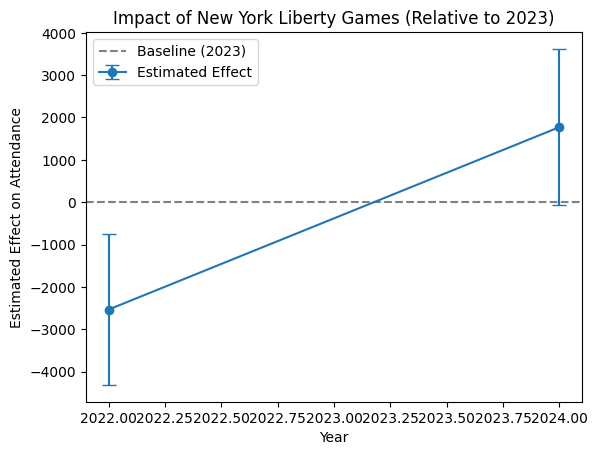

In [ ]:
# New York Liberty (Jonquel Jones; Breanna Stewart)
ny_attendance_df = attendance_df.copy()

# 🚀 2. Create Treatment Variable for New York Liberty Games (2022-2024)
ny_attendance_df['NY_Liberty_Game'] = (ny_attendance_df['Home Team'] == 'New York Liberty') & (ny_attendance_df['Year'].between(2022, 2024))

# 🚀 3. Create Interaction Terms for Each Year (Skip 2023 as the Reference)
for year in [2022, 2024]:
    col_name = f'INX{year}'
    ny_attendance_df[col_name] = ny_attendance_df['NY_Liberty_Game'].astype(int)
    ny_attendance_df.loc[ny_attendance_df['Year'] != year, col_name] = 0

# 🚀 4. Set Index for Panel Data (Team and Year)
ny_attendance_df = ny_attendance_df.set_index(['Home Team', 'Year'])

# 🚀 5. Define and Fit Panel Regression Model
mod = lm.PanelOLS.from_formula(
    'Attendance ~  INX2022 + INX2024 + EntityEffects + TimeEffects - TimeEffects[2023]',
    ny_attendance_df
)
clfe = mod.fit(cov_type='clustered', cluster_entity=True)
print(clfe.summary)

# 🚀 6. Extract Coefficients and Confidence Intervals
res = pd.concat([clfe.params, clfe.std_errors], axis=1)
res.columns = ['parameter', 'std_error']
res['ci'] = res['std_error'] * 1.96  # 95% CI
res['Year'] = [2022, 2024]  # Excluding 2023 as the reference

# Print results table
print("\n📊 Coefficients & Confidence Intervals:")
print(res)

# 🚀 7. Plot the Results
plt.errorbar(x=res['Year'], y=res['parameter'], yerr=res['ci'], fmt='o-', capsize=5, label="Estimated Effect")
plt.axhline(0, linestyle='dashed', color='gray', label="Baseline (2023)")
plt.xlabel("Year")
plt.ylabel("Estimated Effect on Attendance")
plt.title("Impact of New York Liberty Games (Relative to 2023)")
plt.legend()
plt.show()
